In [2]:
import pandas as pd


In [3]:
df = pd.read_csv("emails.csv")

print("Shape:", df.shape)
print(df.head())
print(df.columns.tolist())

Shape: (5172, 3002)
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]
['Email No.', 'the', 'to', 'ect', 'and', '

In [ ]:

df = df.drop_duplicates()

# Separate target and features
y = df["Prediction"].astype(int)

X = df.drop(columns=["Email No.", "Prediction"])

# Convert features to numbers
X = X.apply(pd.to_numeric)

print("Features:", X.shape)
print("Classes:")
print(y.value_counts())

Features: (5172, 3000)
Classes:
Prediction
0    3672
1    1500
Name: count, dtype: int64


In [5]:
from sklearn.model_selection import train_test_split
from scipy.sparse import csr_matrix

X = csr_matrix(X.values)
y = y.values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (4137, 3000)
Test: (1035, 3000)


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.neighbors import KNeighborsClassifier

knn = Pipeline([
    ("tfidf", TfidfTransformer(sublinear_tf=True)),
    ("model", KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute"
    ))
])

knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

print("KNN completed!")

KNN completed!


In [7]:
from sklearn.svm import LinearSVC

svm = Pipeline([
    ("tfidf", TfidfTransformer(sublinear_tf=True)),
    ("model", LinearSVC(C=1.0, random_state=42))
])

svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)

print("SVM completed!")

SVM completed!


In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name, pred in [
    ("KNN", knn_pred),
    ("SVM", svm_pred)
]:
    results.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred, zero_division=0),
        recall_score(y_test, pred, zero_division=0),
        f1_score(y_test, pred, zero_division=0)
    ])

results = pd.DataFrame(
    results,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1"]
)

print(results)

  Model  Accuracy  Precision    Recall        F1
0   KNN  0.976812   0.942308  0.980000  0.960784
1   SVM  0.987440   0.973597  0.983333  0.978441


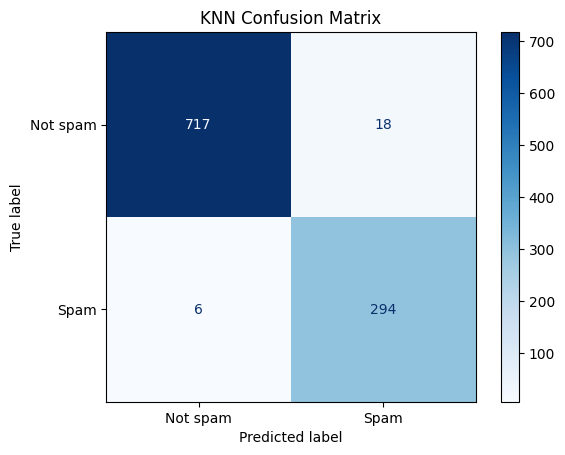

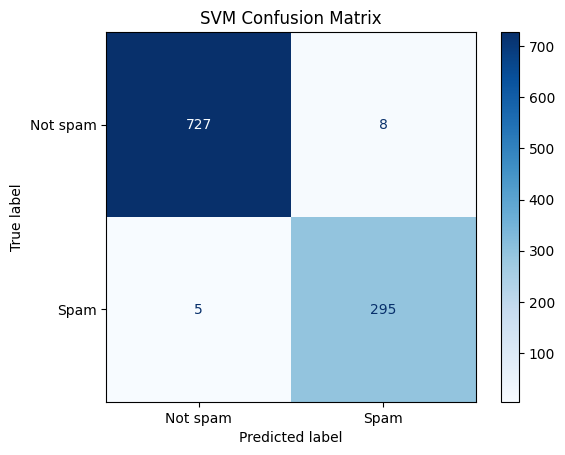

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test, knn_pred,
    display_labels=["Not spam", "Spam"],
    cmap="Blues"
)
plt.title("KNN Confusion Matrix")
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test, svm_pred,
    display_labels=["Not spam", "Spam"],
    cmap="Blues"
)
plt.title("SVM Confusion Matrix")
plt.show()

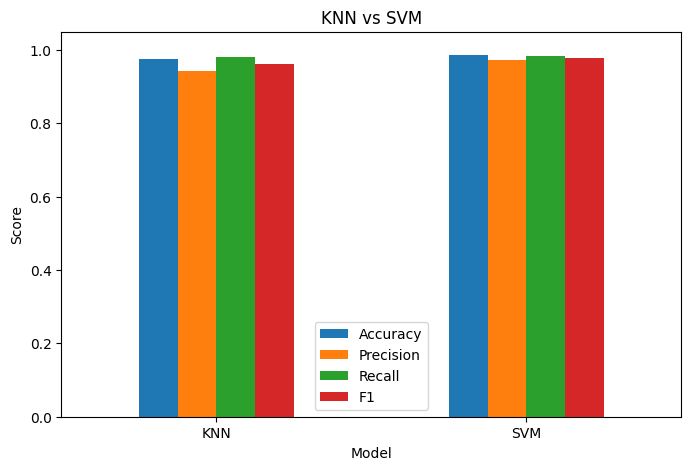

In [10]:
results.set_index("Model").plot(
    kind="bar",
    figsize=(8, 5),
    ylim=(0, 1.05)
)

plt.ylabel("Score")
plt.title("KNN vs SVM")
plt.xticks(rotation=0)
plt.show()